# Average DensGNN adaptive loss curves

Average the recorded **clustering**, **reconstruction**, and **combined** training losses for **CiteSeer, Cora, and PolBlogs**. Each dataset gets its own panel, with a mean curve across saved successful runs and an optional band of ± one sample standard deviation. Separate figures per dataset are also exported.

The notebook reads saved artifacts only; it does not train models or recompute losses. The combined curve uses the logged `total_loss`, whose definition is

$$L_{\mathrm{total}}=L_{\mathrm{reconstruction}}+\gamma L_{\mathrm{clustering}}.$$

During warm-up, the logged clustering loss is genuinely zero and is retained. No smoothing or interpolation is applied. Settings, source files, selected runs, counts per epoch, and a consistency check of the combined-loss definition are exported for inspection.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Markdown


def find_repo_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "scripts/main.py").is_file() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook from within the repository.")


ROOT = find_repo_root()
DATASETS = ["citeseer", "cora", "polblogs"]
DATASET_NAMES = {"citeseer": "CiteSeer", "cora": "Cora", "polblogs": "PolBlogs"}
MODEL = "densgnn"
SEEDS = None  # None: all available seeds; or e.g. [2026, 2027, 2028, 2029, 2030].
# Explicit paths override discovery. Paths are relative to the repository root.
RESULT_PATHS = {}
# Example: {"cora": "results/cora_benchmark_adaptive"}
EPOCH_ALIGNMENT = "common"  # "common": require every selected run; "available": use available runs at each epoch.
SHOW_STD = True
SHOW_INDIVIDUAL_RUNS = False
SHOW_WARMUP_BOUNDARY = True
SAVE_EXPORTS = True
EXPORT_DIR = ROOT / "results/adaptive_loss_curves"
LOSSES = ["clustering_loss", "reconstruction_loss", "total_loss"]
LOSS_NAMES = {"clustering_loss": "Clustering", "reconstruction_loss": "Reconstruction", "total_loss": "Combined"}
COLORS = {"clustering_loss": "#D55E00", "reconstruction_loss": "#0072B2", "total_loss": "#009E73"}
SNAPSHOT_UTC = datetime.now(timezone.utc).isoformat()
if EPOCH_ALIGNMENT not in {"common", "available"}:
    raise ValueError('EPOCH_ALIGNMENT must be "common" or "available".')
if SEEDS is not None and (not isinstance(SEEDS, (list, tuple)) or not SEEDS or len(set(SEEDS)) != len(SEEDS)):
    raise ValueError("SEEDS must be None or a nonempty list of distinct seeds.")


def result_dir(dataset):
    if dataset in RESULT_PATHS:
        value = Path(RESULT_PATHS[dataset]).expanduser()
        return (value if value.is_absolute() else ROOT / value).resolve()
    # Existing folders use *_benchmark_adaptive; also accept the requested *_results_adaptive convention.
    candidates = [ROOT / "results" / f"{dataset}{suffix}" for suffix in ("_results_adaptive", "_benchmark_adaptive")]
    found = [p for p in candidates if p.is_dir()]
    if len(found) != 1:
        raise ValueError(f"Set RESULT_PATHS[{dataset!r}] explicitly; found {len(found)} matching directories: {found}")
    return found[0].resolve()


SOURCES = {dataset: result_dir(dataset) for dataset in DATASETS}
print(f"Snapshot UTC: {SNAPSHOT_UTC}")
display(pd.DataFrame([{"dataset": d, "source": str(p)} for d, p in SOURCES.items()]))

Snapshot UTC: 2026-10-26T19:07:28.890768+00:00


,dataset,source
0,citeseer,/home/gmessias/NodeClusteringAlgorithms/result...
1,cora,/home/gmessias/NodeClusteringAlgorithms/result...
2,polblogs,/home/gmessias/NodeClusteringAlgorithms/result...


## Read and audit histories

Only successful executions of the selected model with adaptive support selection are eligible. Histories are read from `runs/*/<model>/metadata.yaml`; if the history is absent there, the reader tries `metrics.json → algorithm.loss_history`. A native-only history requires the per-run `metrics.csv` to confirm success. The two copies are never counted twice.

Repeated dataset/seed attempts retain the latest successful **usable** history by timestamp-based `run_id`. Missing seeds are kept distinct by run ID. Failed, malformed, filtered, and superseded attempts remain in the audit. Epoch numbers must be explicit, positive integers, without duplicates. Rows with nonfinite/missing loss values are omitted and reported; missing values are never filled with zero.

By default, only epochs observed in **every selected run** of a dataset contribute to its curves (`EPOCH_ALIGNMENT="common"`). The alternative `"available"` allows changing sample counts, which are recorded in `epoch_summary`. Runs are aligned by their actual epoch values, not their array positions. The dashed line marks the boundary after the final warm-up epoch when all selected runs share the same warm-up setting.

In [2]:
def read_run(folder):
    meta_path, native_path = folder / "metadata.yaml", folder / "metrics.json"
    meta, native = {}, {}
    if meta_path.is_file():
        meta = yaml.safe_load(meta_path.read_text(encoding="utf-8")) or {}
        if not isinstance(meta, dict):
            raise ValueError("metadata.yaml is not a mapping")
    history = meta.get("loss_history")
    if not isinstance(history, list) or not history:
        if native_path.is_file():
            native = json.loads(native_path.read_text(encoding="utf-8"))
        algorithm = native.get("algorithm", {})
        history = algorithm.get("loss_history")
        history_file = native_path
    else:
        algorithm = {}
        history_file = meta_path
    status, seed = meta.get("status"), meta.get("seed")
    # A native output file alone does not establish success of the complete benchmark execution.
    if status is None:
        csv_path = folder.parent / "metrics.csv"
        if csv_path.is_file():
            saved = pd.read_csv(csv_path, skipinitialspace=True)
            matches = saved.loc[saved["model"].astype(str).str.strip().eq(MODEL)]
            if len(matches) != 1:
                raise ValueError("Cannot identify a unique model execution in per-run metrics.csv")
            status, seed = matches.iloc[0]["status"], matches.iloc[0].get("seed", seed)
    params = meta.get("model_params") or algorithm
    if not isinstance(params, dict):
        raise ValueError("Model parameters are not a mapping")
    return meta, history, history_file, str(status).strip().lower(), seed, params


def load_loss_histories():
    attempts, histories, issues = [], {}, []
    for dataset, source in SOURCES.items():
        folders = sorted((source / "runs").glob(f"*/{MODEL}"))
        if not folders:
            issues.append({"dataset": dataset, "path": str(source), "detail": "No matching run directories"})
        for folder in folders:
            record = {"attempt_id": len(attempts), "dataset": dataset, "run_id": folder.parent.name,
                      "seed": None, "trial": f"run:{folder.parent.name}", "status": "unreadable",
                      "usable": False, "reason": "", "history_file": "", "n_epochs": 0,
                      "first_epoch": np.nan, "last_epoch": np.nan, "warmup_epochs": np.nan,
                      "gamma": np.nan, "encoder_type": "", "total_loss_consistent": None}
            try:
                meta, history, history_file, status, raw_seed, params = read_run(folder)
                record.update(status=status, history_file=str(history_file))
                seed = pd.to_numeric(raw_seed, errors="coerce")
                if pd.notna(seed):
                    if not np.isfinite(seed) or float(seed) != int(seed):
                        raise ValueError("Seed must be an integer")
                    record.update(seed=int(seed), trial=f"seed:{int(seed)}")
                if meta.get("model", MODEL) != MODEL:
                    raise ValueError("Saved model differs from selected model")
                if status != "success":
                    record["reason"] = "Execution did not succeed"
                elif SEEDS is not None and record["seed"] not in SEEDS:
                    record["reason"] = "Seed excluded by SEEDS"
                elif params.get("point_selection") not in {"adaptive", "adaptative"}:
                    record["reason"] = "Support selection is not confirmed as adaptive"
                elif not isinstance(history, list) or not history:
                    record["reason"] = "No nonempty loss history"
                else:
                    frame = pd.DataFrame(history)
                    missing = {"epoch", *LOSSES} - set(frame.columns)
                    if missing:
                        raise ValueError(f"Missing history fields: {sorted(missing)}")
                    for column in ["epoch", *LOSSES]:
                        frame[column] = pd.to_numeric(frame[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
                    valid_epoch = frame["epoch"].notna() & frame["epoch"].gt(0) & frame["epoch"].mod(1).eq(0)
                    if not valid_epoch.all():
                        raise ValueError("History has missing, nonpositive, or noninteger epoch numbers")
                    frame["epoch"] = frame["epoch"].astype(int)
                    if frame["epoch"].duplicated().any():
                        raise ValueError("Duplicate epoch numbers in one run")
                    finite = frame[LOSSES].notna().all(axis=1)
                    if not finite.all():
                        issues.append({"dataset": dataset, "path": str(history_file),
                                       "detail": f"Omitted {int((~finite).sum())} epoch rows with missing/nonfinite losses"})
                    frame = frame.loc[finite, ["epoch", *LOSSES]].sort_values("epoch").copy()
                    if frame.empty:
                        raise ValueError("History has no complete finite loss rows")
                    gamma = pd.to_numeric(params.get("clustering_loss_gamma"), errors="coerce")
                    warmup = pd.to_numeric(params.get("warmup_epochs"), errors="coerce")
                    record.update(gamma=float(gamma) if pd.notna(gamma) and np.isfinite(gamma) else np.nan,
                                  warmup_epochs=float(warmup) if pd.notna(warmup) and np.isfinite(warmup) else np.nan,
                                  encoder_type=str(params.get("encoder_type", "gcn")),
                                  usable=True, n_epochs=len(frame), first_epoch=int(frame["epoch"].min()),
                                  last_epoch=int(frame["epoch"].max()))
                    if np.isfinite(record["gamma"]):
                        expected = frame["reconstruction_loss"] + record["gamma"] * frame["clustering_loss"]
                        record["total_loss_consistent"] = bool(np.allclose(frame["total_loss"], expected, rtol=1e-5, atol=1e-7))
                        if not record["total_loss_consistent"]:
                            issues.append({"dataset": dataset, "path": str(history_file),
                                           "detail": "Recorded total_loss differs from reconstruction + gamma*clustering; recorded values retained"})
                    frame["attempt_id"] = record["attempt_id"]
                    histories[record["attempt_id"]] = frame
            except (OSError, ValueError, TypeError, KeyError, yaml.YAMLError) as exc:
                record["reason"] = str(exc)
                issues.append({"dataset": dataset, "path": str(folder), "detail": str(exc)})
            attempts.append(record)
    inventory = pd.DataFrame(attempts)
    if inventory.empty or not inventory["usable"].any():
        raise ValueError(f"No usable histories found. Check sources/model/seeds. Details: {issues}")
    selected = (inventory.loc[inventory["usable"]].sort_values(["run_id", "attempt_id"], kind="stable")
                .drop_duplicates(["dataset", "trial"], keep="last").copy())
    inventory["selected"] = inventory["attempt_id"].isin(selected["attempt_id"])
    inventory.loc[inventory["usable"] & ~inventory["selected"], "reason"] = "Superseded usable attempt for the same seed/run"
    frames = []
    for row in selected.itertuples(index=False):
        frame = histories[row.attempt_id].copy()
        frame["dataset"], frame["run_id"], frame["seed"], frame["trial"] = row.dataset, row.run_id, row.seed, row.trial
        frames.append(frame)
    return inventory, selected, pd.concat(frames, ignore_index=True), pd.DataFrame(issues, columns=["dataset", "path", "detail"])


inventory, selected_runs, raw_curves, load_issues = load_loss_histories()
display(selected_runs[["dataset", "seed", "run_id", "n_epochs", "first_epoch", "last_epoch", "warmup_epochs", "gamma", "total_loss_consistent", "history_file"]])
print(f"Selected {len(selected_runs)} successful histories; read {len(raw_curves)} run/epoch observations.")
if not load_issues.empty:
    display(Markdown("**Read/consistency issues**"))
    display(load_issues)
not_selected = inventory.loc[~inventory["selected"]]
if not not_selected.empty:
    display(Markdown("**Excluded and superseded attempts**"))
    display(not_selected[["dataset", "seed", "run_id", "status", "reason"]])

,dataset,seed,run_id,n_epochs,first_epoch,last_epoch,warmup_epochs,gamma,total_loss_consistent,history_file
0,citeseer,2026,20261016_190623_632846_seed2026_run01,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
1,citeseer,2027,20261016_190822_321131_seed2027_run02,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
2,citeseer,2028,20261016_191002_716281_seed2028_run03,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
3,citeseer,2029,20261016_191139_219278_seed2029_run04,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
4,citeseer,2030,20261016_191321_736767_seed2030_run05,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
5,cora,2026,20261016_203926_488754_seed2026_run01,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
6,cora,2027,20261016_204033_755397_seed2027_run02,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
7,cora,2028,20261016_204142_661115_seed2028_run03,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
8,cora,2029,20261016_204250_992035_seed2029_run04,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...
9,cora,2030,20261016_204359_386231_seed2030_run05,200,1,200,5.0,1.0,True,/home/gmessias/NodeClusteringAlgorithms/result...


Selected 15 successful histories; read 3000 run/epoch observations.


In [3]:
run_counts = selected_runs.groupby("dataset").size().to_dict()
long_curves = raw_curves.melt(id_vars=["dataset", "run_id", "seed", "trial", "attempt_id", "epoch"],
                             value_vars=LOSSES, var_name="loss", value_name="value")
epoch_summary = long_curves.groupby(["dataset", "loss", "epoch"], as_index=False).agg(
    mean=("value", "mean"), std=("value", "std"), n=("value", "count")
)
epoch_summary["n_selected_runs"] = epoch_summary["dataset"].map(run_counts)
epoch_summary["plotted"] = epoch_summary["n"].eq(epoch_summary["n_selected_runs"]) if EPOCH_ALIGNMENT == "common" else True
plot_summary = epoch_summary.loc[epoch_summary["plotted"]].copy()
coverage_rows = []
for dataset in DATASETS:
    chosen = selected_runs.loc[selected_runs["dataset"].eq(dataset)]
    epochs = plot_summary.loc[plot_summary["dataset"].eq(dataset), "epoch"]
    coverage_rows.append({"dataset": dataset, "n_runs": len(chosen), "seeds": chosen["seed"].tolist(),
                          "plotted_first_epoch": epochs.min(), "plotted_last_epoch": epochs.max(),
                          "plotted_epochs": epochs.nunique(), "warmup_values": chosen["warmup_epochs"].dropna().unique().tolist(),
                          "gamma_values": chosen["gamma"].dropna().unique().tolist()})
coverage = pd.DataFrame(coverage_rows)
display(coverage)
for row in coverage.itertuples(index=False):
    if len(row.gamma_values) > 1:
        warnings.warn(f"{row.dataset}: multiple gamma values; inspect selected run settings before comparing total losses.")
    if row.n_runs and not row.plotted_epochs:
        warnings.warn(f"{row.dataset}: selected histories have no common epochs; inspect coverage or EPOCH_ALIGNMENT.")
final_summary = plot_summary.sort_values("epoch").groupby(["dataset", "loss"], as_index=False).tail(1)
display(Markdown("**Final plotted epoch: mean, sample SD and run count**"))
display(final_summary[["dataset", "loss", "epoch", "mean", "std", "n"]])

,dataset,n_runs,seeds,plotted_first_epoch,plotted_last_epoch,plotted_epochs,warmup_values,gamma_values
0,citeseer,5,"[2026, 2027, 2028, 2029, 2030]",1,200,200,[5.0],[1.0]
1,cora,5,"[2026, 2027, 2028, 2029, 2030]",1,200,200,[5.0],[1.0]
2,polblogs,5,"[2026, 2027, 2028, 2029, 2030]",1,200,200,[20.0],[1.0]


**Final plotted epoch: mean, sample SD and run count**

,dataset,loss,epoch,mean,std,n
599,citeseer,total_loss,200,1.015369,0.063896,5
399,citeseer,reconstruction_loss,200,0.866886,0.026905,5
1799,polblogs,total_loss,200,1.176274,0.013942,5
1199,cora,total_loss,200,1.149901,0.017158,5
1599,polblogs,reconstruction_loss,200,0.967147,0.006383,5
1399,polblogs,clustering_loss,200,0.209128,0.016659,5
999,cora,reconstruction_loss,200,0.910571,0.015243,5
799,cora,clustering_loss,200,0.239329,0.021823,5
199,citeseer,clustering_loss,200,0.148483,0.040035,5


## Plot the average losses

Each colored line is the arithmetic mean at that epoch. Shaded bands show ± one **sample** standard deviation (`ddof=1`), not a confidence interval. A single contributing run has no SD band. Thin individual traces can be enabled with `SHOW_INDIVIDUAL_RUNS=True`. The combined loss is read from the logs rather than reconstructed from averaged components.

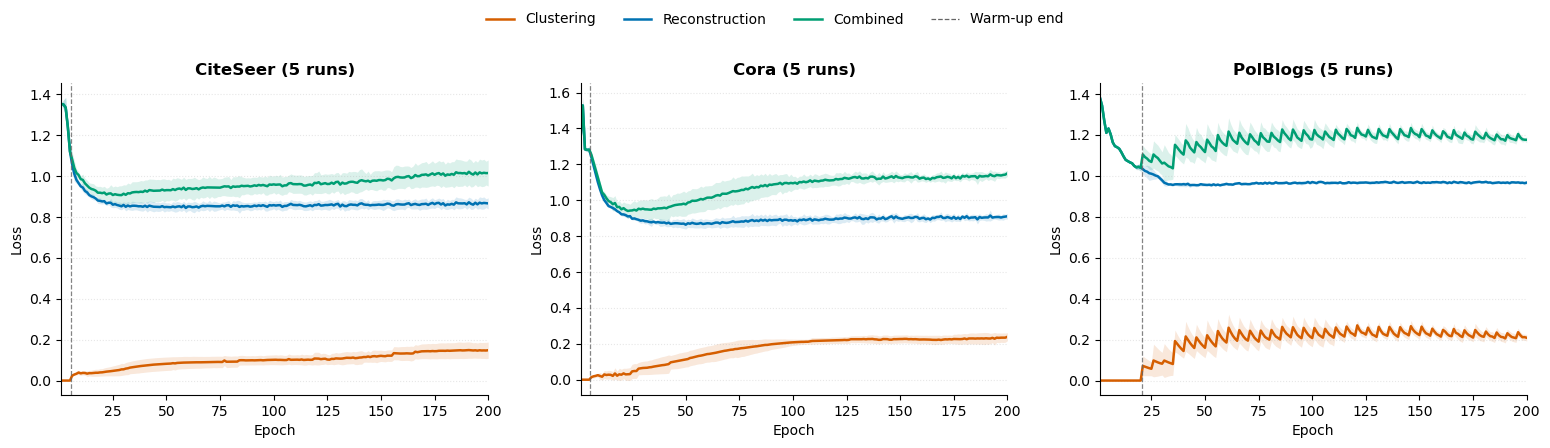

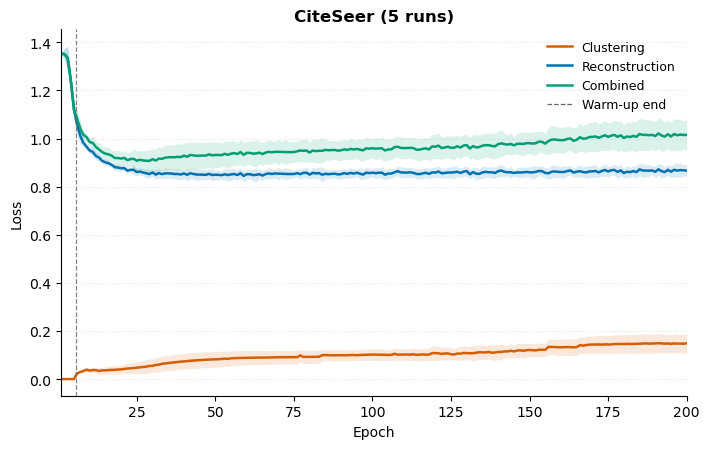

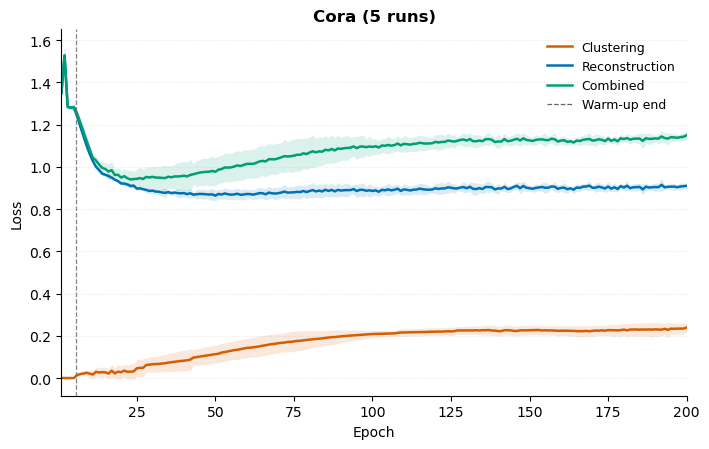

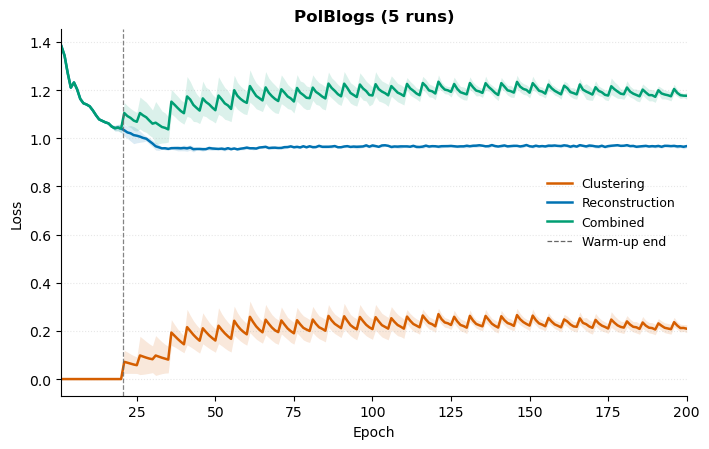

In [4]:
def draw_dataset_losses(axis, dataset):
    dataset_summary = plot_summary.loc[plot_summary["dataset"].eq(dataset)]
    if dataset_summary.empty:
        axis.text(0.5, 0.5, "No usable average loss curve", ha="center", va="center", transform=axis.transAxes)
    for loss in LOSSES:
        curve = dataset_summary.loc[dataset_summary["loss"].eq(loss)].sort_values("epoch")
        if curve.empty:
            continue
        if SHOW_INDIVIDUAL_RUNS:
            allowed = set(curve["epoch"])
            for _, run in raw_curves.loc[raw_curves["dataset"].eq(dataset)].groupby("attempt_id"):
                run = run.loc[run["epoch"].isin(allowed)].sort_values("epoch")
                axis.plot(run["epoch"], run[loss], color=COLORS[loss], alpha=0.13, linewidth=0.7)
        x, mean, std = (curve[column].to_numpy(dtype=float) for column in ["epoch", "mean", "std"])
        axis.plot(x, mean, color=COLORS[loss], label=LOSS_NAMES[loss], linewidth=1.8)
        if SHOW_STD:
            axis.fill_between(x, mean - std, mean + std, where=np.isfinite(std),
                              color=COLORS[loss], alpha=0.14, linewidth=0)
    chosen = selected_runs.loc[selected_runs["dataset"].eq(dataset)]
    warmup = chosen["warmup_epochs"].dropna().unique()
    if SHOW_WARMUP_BOUNDARY and len(warmup) == 1 and not dataset_summary.empty:
        boundary = float(warmup[0]) + 0.5
        if dataset_summary["epoch"].min() <= boundary <= dataset_summary["epoch"].max():
            axis.axvline(boundary, linestyle="--", color="#666666", linewidth=0.9, alpha=0.8)
    axis.set_title(f"{DATASET_NAMES.get(dataset, dataset)} ({len(chosen)} runs)", fontweight="bold")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Loss")
    axis.grid(axis="y", linestyle=":", alpha=0.3)
    axis.spines[["top", "right"]].set_visible(False)
    if not dataset_summary.empty:
        first, last = dataset_summary["epoch"].min(), dataset_summary["epoch"].max()
        axis.set_xlim((first, last) if first < last else (first - 0.5, last + 0.5))


legend_handles = [Line2D([0], [0], color=COLORS[loss], linewidth=1.8, label=LOSS_NAMES[loss]) for loss in LOSSES]
if SHOW_WARMUP_BOUNDARY:
    legend_handles.append(Line2D([0], [0], color="#666666", linestyle="--", linewidth=0.9, label="Warm-up end"))
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 4.5), squeeze=False)
for axis, dataset in zip(axes.flat, DATASETS):
    draw_dataset_losses(axis, dataset)
fig.legend(handles=legend_handles, loc="upper center", ncol=len(legend_handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.90), w_pad=2)
plt.show()
plt.close(fig)

individual_figures = {}
for dataset in DATASETS:
    single, axis = plt.subplots(figsize=(7.2, 4.6))
    draw_dataset_losses(axis, dataset)
    axis.legend(handles=legend_handles, frameon=False, fontsize=9)
    single.tight_layout()
    individual_figures[dataset] = single
    plt.show()
    plt.close(single)

## Export the snapshot

PNG, PDF and SVG figures are written to `results/adaptive_loss_curves/`: `average_loss_curves.*` contains the three panels; `<dataset>_loss_curves.*` contains one dataset. CSVs record the full selected histories, epoch-level averages/SD/counts, plotted epochs, selected runs, exclusions and read issues. The metadata file records source paths and settings. Re-execution replaces these analysis exports and only reads the original run artifacts.

In [5]:
if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "pdf", "svg"):
        fig.savefig(EXPORT_DIR / f"average_loss_curves.{extension}", dpi=220, bbox_inches="tight")
        for dataset, figure in individual_figures.items():
            figure.savefig(EXPORT_DIR / f"{dataset}_loss_curves.{extension}", dpi=220, bbox_inches="tight")
    for name, frame in {"run_inventory": inventory, "selected_runs": selected_runs, "raw_curves": raw_curves,
                        "epoch_summary": epoch_summary, "plotted_summary": plot_summary,
                        "coverage": coverage, "final_epoch_summary": final_summary, "load_issues": load_issues}.items():
        frame.to_csv(EXPORT_DIR / f"{name}.csv", index=False)
    metadata = {
        "snapshot_utc": SNAPSHOT_UTC, "model": MODEL, "datasets": DATASETS, "seeds_filter": SEEDS,
        "sources": {d: str(p) for d, p in SOURCES.items()},
        "history_files": selected_runs["history_file"].tolist(),
        "selected_run_ids": selected_runs["run_id"].tolist(), "epoch_alignment": EPOCH_ALIGNMENT,
        "show_sample_sd": SHOW_STD, "show_individual_runs": SHOW_INDIVIDUAL_RUNS,
        "show_warmup_boundary": SHOW_WARMUP_BOUNDARY,
        "combined_loss": "recorded total_loss = reconstruction_loss + gamma * clustering_loss",
        "smoothing": None, "interpolation": None,
        "retry_policy": "latest successful usable history per dataset/seed; missing seeds identified by run_id",
        "versions": {"numpy": np.__version__, "pandas": pd.__version__},
    }
    (EXPORT_DIR / "analysis_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(f"Saved figures and audit tables to: {EXPORT_DIR}")
else:
    print("Exports disabled; curves and tables remain visible in the notebook.")

Saved figures and audit tables to: /home/gmessias/NodeClusteringAlgorithms/results/adaptive_loss_curves


## Loss combinada: três painéis quadrados em TikZ

A figura abaixo usa **somente a média de `total_loss`**, com CiteSeer, Cora e PolBlogs lado a lado. Cada área de desenho mede **3 × 3 cm**, com a mesma escala vertical para facilitar a comparação. Não há suavização, interpolação, bandas de desvio padrão ou curvas adicionais.

Os pontos vêm de `plot_summary`, mantendo as mesmas runs e a política de alinhamento das figuras anteriores. Ajuste `TIKZ_PANEL_SIZE_CM` para mudar o tamanho dos quadrados. `TIKZ_SHARED_Y_SCALE=False` permite que cada painel use sua própria escala vertical.

São exportados `combined_loss_tikz.tex` (trecho para o artigo), `combined_loss_tikz_standalone.tex` (documento completo), `combined_loss_tikz_data.csv` e os metadados. Se houver `tectonic` ou `pdflatex`, o documento completo é compilado; com `pdftoppm`, a prévia do PDF aparece no notebook.

No preâmbulo do artigo:

```latex
\usepackage{pgfplots}
\usepgfplotslibrary{groupplots}
\pgfplotsset{compat=1.18}
```

Para inserir (copie o trecho `.tex` para a pasta `figures/` do artigo):

```latex
\begin{figure*}[t]
    \centering
    \input{figures/combined_loss_tikz.tex}
    \caption{Mean combined training loss of DensGNN with adaptive support
    selection on CiteSeer, Cora, and PolBlogs. Curves show per-epoch means
    over successful runs, without smoothing.}
    \label{fig:combined-loss-curves}
\end{figure*}
```

Trecho TikZ: /home/gmessias/NodeClusteringAlgorithms/results/adaptive_loss_curves/combined_loss_tikz.tex
Documento completo: /home/gmessias/NodeClusteringAlgorithms/results/adaptive_loss_curves/combined_loss_tikz_standalone.tex


/home/gmessias/NodeClusteringAlgorithms/results/adaptive_loss_curves/combined_loss_tikz_standalone.pdf

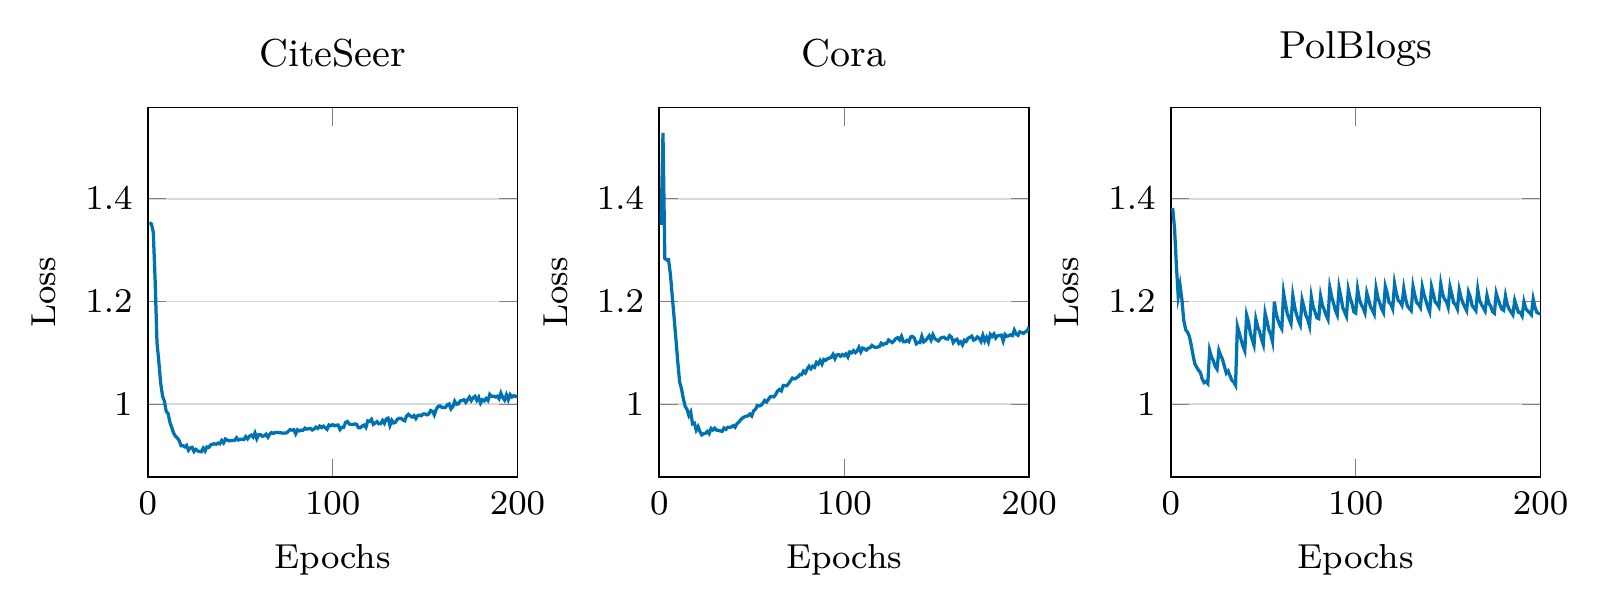

In [3]:
import html
import shutil
import subprocess
from IPython.display import FileLink, HTML, Image as TikzPreview

TIKZ_PANEL_SIZE_CM = 3.0
TIKZ_PANEL_GAP_CM = 1.15
TIKZ_SHARED_Y_SCALE = True
TIKZ_LINE_COLOR = "#0072B2"
TIKZ_COMPILE_IF_AVAILABLE = True


def tex_escape_loss(text):
    escaped = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
               "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}
    return "".join(escaped.get(char, char) for char in str(text))


def combined_loss_tikz(summary):
    if TIKZ_PANEL_SIZE_CM <= 0 or TIKZ_PANEL_GAP_CM <= 0:
        raise ValueError("Panel size and gap must be positive.")
    data = summary.loc[summary["loss"].eq("total_loss") & summary["dataset"].isin(DATASETS)].copy()
    if data.empty:
        raise ValueError("No combined loss data; execute the reading and aggregation cells first.")
    for dataset in DATASETS:
        curve = data.loc[data["dataset"].eq(dataset)]
        if curve.empty or not np.isfinite(curve[["epoch", "mean"]].to_numpy(dtype=float)).all():
            raise ValueError(f"Missing/nonfinite combined loss curve for {dataset}.")
        if curve["epoch"].duplicated().any():
            raise ValueError(f"Duplicate combined-loss epoch in {dataset}.")
    number = lambda value: format(float(value), ".12g")
    end_epoch = int(data["epoch"].max())
    ticks = sorted({0, end_epoch // 2, end_epoch})
    low, high = float(data["mean"].min()), float(data["mean"].max())
    padding = (high - low) * 0.08 if high > low else max(abs(high) * 0.08, 0.01)
    options = [
        "group style={group size=" + str(len(DATASETS)) + " by 1, horizontal sep=" + number(TIKZ_PANEL_GAP_CM) + "cm}",
        "width=" + number(TIKZ_PANEL_SIZE_CM) + "cm", "height=" + number(TIKZ_PANEL_SIZE_CM) + "cm",
        "scale only axis", r"/tikz/font=\footnotesize", r"title style={font=\small}",
        "axis lines=box", "tick align=inside", "tick pos=both",
        "xlabel={Epochs}", "ylabel={Loss}", "xmin=0", "xmax=" + str(end_epoch),
        "xtick={" + ",".join(str(tick) for tick in ticks) + "}",
        "ymajorgrids=true", "grid style={draw=gray!30}", "scaled ticks=false",
        r"yticklabel style={/pgf/number format/fixed,/pgf/number format/precision=2}",
    ]
    if TIKZ_SHARED_Y_SCALE:
        options.extend(["ymin=" + number(low - padding), "ymax=" + number(high + padding)])
    lines = [r"% Preamble: \usepackage{pgfplots}", r"% \usepgfplotslibrary{groupplots}",
             r"% \pgfplotsset{compat=1.18}", r"\begin{tikzpicture}",
             r"\definecolor{combinedlossblue}{HTML}{" + TIKZ_LINE_COLOR.lstrip("#") + "}",
             r"\begin{groupplot}[", "    " + ",\n    ".join(options), "]"]
    frames = []
    for dataset in DATASETS:
        curve = data.loc[data["dataset"].eq(dataset)].sort_values("epoch")
        frames.append(curve)
        lines.append(r"\nextgroupplot[title={" + tex_escape_loss(DATASET_NAMES.get(dataset, dataset)) + "}]")
        lines.append(r"\addplot[color=combinedlossblue,line width=0.75pt,no marks] coordinates {")
        lines.extend("    (" + number(row.epoch) + "," + number(row.mean) + ")" for row in curve.itertuples(index=False))
        lines.append("};")
    lines.extend([r"\end{groupplot}", r"\end{tikzpicture}"])
    return "\n".join(lines) + "\n", pd.concat(frames, ignore_index=True)


combined_tikz_code, combined_tikz_data = combined_loss_tikz(plot_summary)
combined_tikz_document = "\n".join([
    r"\documentclass[tikz,border=4pt]{standalone}", r"\usepackage[T1]{fontenc}",
    r"\usepackage{pgfplots}", r"\usepgfplotslibrary{groupplots}", r"\pgfplotsset{compat=1.18}",
    r"\begin{document}", combined_tikz_code, r"\end{document}", "",
])
display(HTML("<details><summary>Ver o código TikZ completo</summary><pre>"
             + html.escape(combined_tikz_code) + "</pre></details>"))
if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    snippet_path = EXPORT_DIR / "combined_loss_tikz.tex"
    standalone_path = EXPORT_DIR / "combined_loss_tikz_standalone.tex"
    snippet_path.write_text(combined_tikz_code, encoding="utf-8")
    standalone_path.write_text(combined_tikz_document, encoding="utf-8")
    combined_tikz_data.to_csv(EXPORT_DIR / "combined_loss_tikz_data.csv", index=False)
    tikz_metadata = {
        "snapshot_utc": SNAPSHOT_UTC, "datasets": DATASETS, "loss": "total_loss", "statistic": "mean",
        "panel_size_cm": TIKZ_PANEL_SIZE_CM, "panel_gap_cm": TIKZ_PANEL_GAP_CM,
        "shared_y_scale": TIKZ_SHARED_Y_SCALE, "line_color": TIKZ_LINE_COLOR,
        "smoothing": None, "interpolation": None, "epoch_alignment": EPOCH_ALIGNMENT,
        "sources": {d: str(p) for d, p in SOURCES.items()},
        "runs": {d: selected_runs.loc[selected_runs["dataset"].eq(d), "run_id"].tolist() for d in DATASETS},
    }
    (EXPORT_DIR / "combined_loss_tikz_metadata.json").write_text(json.dumps(tikz_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(f"Trecho TikZ: {snippet_path}\nDocumento completo: {standalone_path}")
    engine = (shutil.which("tectonic") or shutil.which("pdflatex")) if TIKZ_COMPILE_IF_AVAILABLE else None
    if engine:
        command = ([engine, "--outdir", str(EXPORT_DIR), str(standalone_path)] if Path(engine).name == "tectonic" else
                   [engine, "-interaction=nonstopmode", "-halt-on-error", "-output-directory", str(EXPORT_DIR), str(standalone_path)])
        try:
            result = subprocess.run(command, cwd=EXPORT_DIR, capture_output=True, text=True, timeout=300)
            (EXPORT_DIR / "combined_loss_tikz_compile.log").write_text(result.stdout + "\n" + result.stderr, encoding="utf-8")
            if result.returncode:
                print("Falha na compilação; consulte combined_loss_tikz_compile.log. Os arquivos .tex foram preservados.")
            else:
                pdf_path = standalone_path.with_suffix(".pdf")
                display(FileLink(str(pdf_path)))
                renderer = shutil.which("pdftoppm")
                if renderer:
                    preview = subprocess.run([renderer, "-singlefile", "-png", "-scale-to", "1600",
                                              str(pdf_path), str(standalone_path.with_suffix(""))],
                                             capture_output=True, text=True, timeout=30)
                    if preview.returncode == 0:
                        display(TikzPreview(filename=str(standalone_path.with_suffix(".png")), width=1000))
        except (OSError, subprocess.TimeoutExpired) as exc:
            print(f"Fontes exportados; compilação/prévia não concluída: {exc}")
    else:
        print("Fontes exportados. Compile o documento standalone com pdflatex ou tectonic para gerar o PDF.")
else:
    print("SAVE_EXPORTS=False; o código TikZ está disponível acima, sem gravar arquivos.")